# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [11]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [12]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [13]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [14]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

def parse_dates(series, min_success_rate=0.95):
    n_total = len(series)
    n_already_missing = series.isna().sum()

    converted = pd.to_datetime(
        series,
        errors='coerce',
        format='mixed',
        dayfirst=True
    )

    n_failed = (
        converted.isna().sum()
        - n_already_missing
    )

    n_valid = n_total - n_already_missing
    success_rate = (
        (n_valid - n_failed) / n_valid
        if n_valid > 0 else 1.0
    )

    report = {
        'n_total': n_total,
        'n_already_missing': int(n_already_missing),
        'n_failed': int(n_failed),
        'success_rate': success_rate,
        'min_date': converted.min(),
        'max_date': converted.max()
    }

    if success_rate < min_success_rate:
        raise ValueError(
            f"Taux de réussite insuffisant : "
            f"{success_rate:.2%} < {min_success_rate:.2%}"
        )

    return converted, report

# order_dates, report = parse_dates(raw_sales['date_commande'])
# print(report)

---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [15]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-11-02 00:00:00,2024,11,Saturday,44,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [16]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [17]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).

# Copier le DataFrame pour ne pas modifier l'original
features = raw_sales.copy()

# Utiliser les dates converties de Q1
features['date_commande'] = order_dates

# 1. Période de la journée
heure = features['date_commande'].dt.hour

features['periode_journee'] = np.select(
    [
        heure < 12,
        heure < 18
    ],
    [
        'matin',
        'apres-midi'
    ],
    default='soir'
)

# 2. Les trois derniers jours du mois
features['est_fin_de_mois'] = (
    features['date_commande'].dt.day
    >= (
        features['date_commande'].dt.days_in_month - 2
    )
)

# 3. Nombre de jours depuis la première commande
premiere_commande = features['date_commande'].min()

features['jours_depuis_debut'] = (
    features['date_commande'] - premiere_commande
).dt.days

# 4. Jointure avec le référentiel clients
clients = pd.read_csv(RAW_DIR / 'clients.csv')

clients['date_inscription'] = pd.to_datetime(
    clients['date_inscription'],
    errors='coerce',
    format='mixed',
    dayfirst=True
)

features = features.merge(
    clients[['id_client', 'date_inscription']],
    on='id_client',
    how='left'
)

# Ancienneté du client en jours
features['anciennete_client_jours'] = (
    features['date_commande'] - features['date_inscription']
).dt.days

print(features[
    [
        'date_commande',
        'periode_journee',
        'est_fin_de_mois',
        'jours_depuis_debut',
        'anciennete_client_jours'
    ]
].head())

        date_commande periode_journee  est_fin_de_mois  jours_depuis_debut  anciennete_client_jours
0 2024-01-18 19:53:00            soir            False               382.0                   1005.0
1 2024-01-08 00:00:00           matin            False               372.0                    -42.0
2 2023-04-15 00:00:00           matin            False               104.0                   1511.0
3 2024-11-06 00:00:00           matin            False               675.0                   1985.0
4 2024-11-02 00:00:00           matin            False               671.0                   1400.0


In [21]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.

# Convertir les colonnes numériques
features['quantite'] = pd.to_numeric(
    features['quantite'],
    errors='coerce'
)

features['prix_unitaire'] = pd.to_numeric(
    features['prix_unitaire'],
    errors='coerce'
)

features['remise_pct'] = pd.to_numeric(
    features['remise_pct'],
    errors='coerce'
)

# Les remises manquantes = 0 %
features['remise_pct'] = features['remise_pct'].fillna(0)

# Calcul du montant après remise
features['montant'] = (
    features['quantite']
    * features['prix_unitaire']
    * (1 - features['remise_pct'] / 100)
)

# Montant moyen selon semaine / week-end
moyenne_weekend = (
    features.groupby('est_weekend')['montant']
    .mean()
)

print("Montant moyen selon le week-end :")
print(moyenne_weekend)

# Nom du jour
jours = {
    0: 'lundi',
    1: 'mardi',
    2: 'mercredi',
    3: 'jeudi',
    4: 'vendredi',
    5: 'samedi',
    6: 'dimanche'
}

features['nom_jour'] = (
    features['date_commande']
    .dt.dayofweek
    .map(jours)
)

# Montant moyen par jour
moyenne_jour = (
    features.groupby('nom_jour')['montant']
    .mean()
    .reindex([
        'lundi',
        'mardi',
        'mercredi',
        'jeudi',
        'vendredi',
        'samedi',
        'dimanche'
    ])
)

print("\nMontant moyen par jour :")
print(moyenne_jour)

Montant moyen selon le week-end :
est_weekend
False    2202.101930
True     3526.313432
Name: montant, dtype: float64

Montant moyen par jour :
nom_jour
lundi       1870.596882
mardi       1990.371958
mercredi    2521.428091
jeudi       2526.621842
vendredi    2119.926143
samedi      3166.874252
dimanche    3880.547921
Name: montant, dtype: float64


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [22]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [23]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


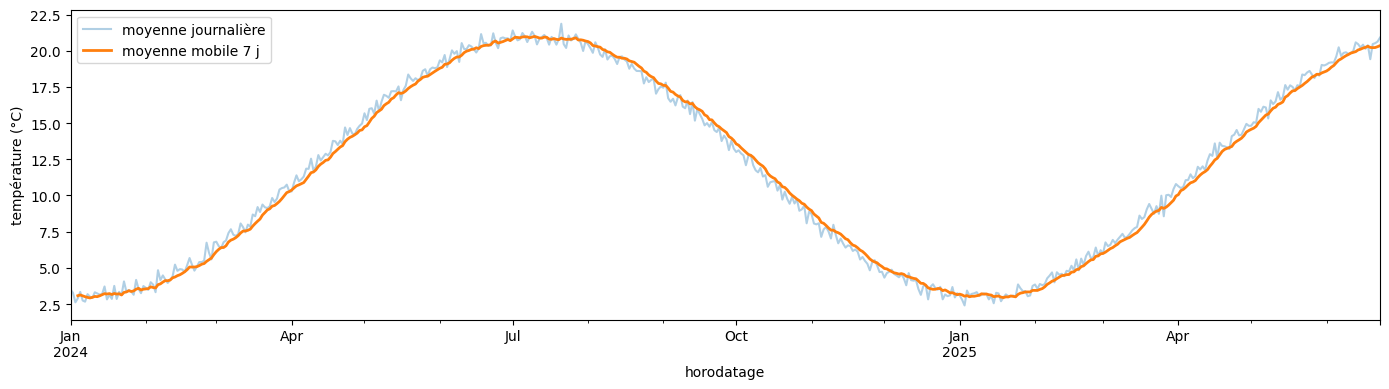

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

In [29]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.

# Sélectionner CAP-B
cap_b = sensors[sensors['id_capteur'] == 'CAP-B'].copy()

# Convertir l'horodatage en datetime
cap_b['horodatage'] = pd.to_datetime(
    cap_b['horodatage'],
    errors='coerce'
)

# Mettre l'horodatage en index et trier
cap_b = cap_b.set_index('horodatage').sort_index()

# Créer une plage horaire complète
horaire = pd.date_range(
    start=cap_b.index.min(),
    end=cap_b.index.max(),
    freq='h'
)

# Réindexer pour faire apparaître les heures sans mesure
cap_b = cap_b.reindex(horaire)

# Repérer les heures sans mesure
sans_mesure = cap_b['temperature_c'].isna()

# Identifier les suites de valeurs manquantes
groupes = sans_mesure.ne(sans_mesure.shift()).cumsum()

# Regrouper les périodes sans mesure
pannes = (
    cap_b[sans_mesure]
    .groupby(groupes[sans_mesure])
    .agg(
        debut=('temperature_c', lambda x: x.index.min()),
        fin=('temperature_c', lambda x: x.index.max()),
        nb_heures=('temperature_c', 'size')
    )
)

# Garder les périodes de plus de 24 heures
pannes = pannes[pannes['nb_heures'] > 24]

print("Plages de panne de CAP-B (> 24 h) :")
print(pannes)

Plages de panne de CAP-B (> 24 h) :
                   debut                 fin  nb_heures
temperature_c                                          
212           2024-06-03 2024-06-13 23:00:00        264


In [30]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.

# Sélectionner CAP-C
cap_c = sensors[sensors['id_capteur'] == 'CAP-C'].copy()

# Trier par date
cap_c['horodatage'] = pd.to_datetime(
    cap_c['horodatage'],
    errors='coerce'
)
cap_c = cap_c.sort_values('horodatage')

# Repérer les changements de valeur
changement = cap_c['temperature_c'].ne(
    cap_c['temperature_c'].shift()
)

# Créer un numéro de groupe pour chaque suite de valeurs identiques
groupes = changement.cumsum()

# Calculer la longueur de chaque suite
longueurs = cap_c.groupby(groupes)['temperature_c'].transform('size')

# Garder les suites constantes de plus de 24 relevés
capteur_bloque = cap_c[longueurs > 24].copy()

print("Périodes où CAP-C est bloqué (> 24 relevés consécutifs) :")
print(capteur_bloque[['horodatage', 'temperature_c']])

Périodes où CAP-C est bloqué (> 24 relevés consécutifs) :
               horodatage  temperature_c
31969 2024-09-10 01:00:00           17.4
31970 2024-09-10 02:00:00           17.4
31971 2024-09-10 03:00:00           17.4
31972 2024-09-10 04:00:00           17.4
31973 2024-09-10 05:00:00           17.4
...                   ...            ...
32069 2024-09-14 05:00:00           17.4
32070 2024-09-14 06:00:00           17.4
32071 2024-09-14 07:00:00           17.4
32072 2024-09-14 08:00:00           17.4
32073 2024-09-14 09:00:00           17.4

[104 rows x 2 columns]


In [31]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.

# Vérifier que la date est bien au format datetime
sales['date_commande'] = pd.to_datetime(
    sales['date_commande'],
    errors='coerce',
    format='mixed',
    dayfirst=True
)

# Calculer le montant de chaque vente si nécessaire
sales['quantite'] = pd.to_numeric(sales['quantite'], errors='coerce')
sales['prix_unitaire'] = pd.to_numeric(sales['prix_unitaire'], errors='coerce')
sales['remise_pct'] = pd.to_numeric(sales['remise_pct'], errors='coerce').fillna(0)

sales['montant'] = (
    sales['quantite']
    * sales['prix_unitaire']
    * (1 - sales['remise_pct'] / 100)
)

# Agrégation hebdomadaire
ca_semaine = (
    sales.set_index('date_commande')['montant']
    .resample('W')
    .sum()
)

print("Chiffre d'affaires hebdomadaire :")
print(ca_semaine.head())

Chiffre d'affaires hebdomadaire :
date_commande
2023-01-01    2.759258e+04
2023-01-08    1.638991e+05
2023-01-15    1.767457e+05
2023-01-22    1.063611e+06
2023-01-29    9.432520e+05
Freq: W-SUN, Name: montant, dtype: float64


---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.